# A Transformer-Based Approach for Raw EEG Classification

## 1. Setup and Imports

Import necessary libraries and set up the environment.



In [1]:
%load_ext autoreload
%autoreload 2 
#%autoreload 2 fa in modo che, ogni volta che modifichi e salvi un file .py, Jupyter ricarichi automaticamente le modifiche nel notebook senza chiederti di riavviare il kernel!†

In [2]:
import numpy as np
from pathlib import Path
import re
import sys
import random

src_path = Path('../src/eeg-bci-transformer-pipeline').resolve()
if str(src_path) not in sys.path:
    sys.path.append(str(src_path))

from datapreprocessing import EEGpreprocessing, EEGDataset
from train import  EEGTrainer
from models import F_CTrans , F_CTrans_modified


import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import mne
import os
from sklearn.model_selection import KFold,GroupKFold
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

# Eseguiamo il seed globalmente per tutto il notebook
set_seed(42)

## 2. Data Loading and Preprocessing

Load the PhysioNet EEG Motor Movement/Imagery Dataset 

In [4]:
CURRENT_DIR = Path.cwd()

DATASET_PATH = (CURRENT_DIR.parent / "data" / "MotorImagery(04,08,012)") 

print(f"Dataset path used: {DATASET_PATH}")

edf_files = sorted(DATASET_PATH.glob("**/*.edf"))

file_records = []
for edf_path in edf_files:
    filename = edf_path.stem
    match = re.search(r'S(\d+)', filename, re.IGNORECASE)
    if match:
        subj_id = int(match.group(1))
        file_records.append({'path': edf_path, 'subject_id': subj_id})

file_subject_ids = np.array([r['subject_id'] for r in file_records])
unique_subjects = np.unique(file_subject_ids)

np.random.seed(42)
shuffled_subjects = unique_subjects.copy()
np.random.shuffle(shuffled_subjects)

test_subjects = set(shuffled_subjects[:11])
train_val_subjects = set(shuffled_subjects[11:])

train_val_records = [r for r in file_records if r['subject_id'] in train_val_subjects]
test_records = [r for r in file_records if r['subject_id'] in test_subjects]

print(f"File EDF for Train/Validation: {len(train_val_records)}")
print(f"File EDF for TEST: {len(test_records)}")


Dataset path used: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)
File EDF for Train/Validation: 294
File EDF for TEST: 33


Apply preprocessing  #momontaneamente lo faccio solo sul train/val perchè non sono sicura vada fatto sul test, riparlarne con luca

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import mne

X_raw_list = []
y_list = []
subject_ids_list = []
psd_records = []  

for i, rec in enumerate(train_val_records):
    file_path = rec['path']
    subj_id = rec['subject_id']

    print(f"Subject Processing {subj_id} - File: {file_path}")

    try:
        raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError
    except Exception as e:
        print(f"❌ ERROR: Unable to read Subject file {subj_id}!")
        print(f"   Path: {file_path}")
        print(f"   Detail: {e}")
        continue

    pipeline = EEGpreprocessing(raw)
    pipeline.bandpassfilter(l_freq=8.0, h_freq=30.0, target_sfreq=160.0)
    epochs_mne = pipeline.epoching(tmin=0.0, tmax=4.0)

    if len(epochs_mne) == 0:
        print(f"⚠️ Warning: No epoch found for Subject {subj_id}. Jump.")
        continue
    
    psd_object = epochs_mne.compute_psd(fmin=1, fmax=40, method='welch', verbose=False)
    psd_values, freqs = psd_object.get_data(return_freqs=True) 
    
    psd_records.append({
        'subject_id': subj_id,
        'frequencies': freqs,
        'psd_data': psd_values,
        'mean_power_per_channel': np.mean(psd_values, axis=(0, 2))
    })

    X_raw = epochs_mne.get_data(copy=True) # Shape: (n_trials, 64, 480)

    # Label extraction and mapping (Left = 0, Right = 1)
    y = epochs_mne.events[:, -1]
    event_id = epochs_mne.event_id
    
    labels = np.zeros(len(y), dtype=np.int64)
    if 'Left' in event_id and event_id['Left'] in y:
        labels[y == event_id['Left']] = 0
    if 'Right' in event_id and event_id['Right'] in y:
        labels[y == event_id['Right']] = 1

   
    X_raw_list.append(X_raw)
    y_list.append(labels)
    subject_ids_list.extend([subj_id] * len(X_raw))

print(" Extraction cycle completed successfully!")
print(f"Subjects processed correctly: {len(X_raw_list)}")

Subject Processing 1 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S001/S001R04.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 1 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S001/S001R08.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 1 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S001/S001R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
N

/tmp/ipykernel_138300/2250886293.py:17: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
1 bad epochs dropped
Subject Processing 35 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S035/S035R04.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
10 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 10 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 35 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S035/S035R08.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']


/tmp/ipykernel_138300/2250886293.py:17: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 35 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S035/S035R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 36 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S036/S036R04.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs 

/tmp/ipykernel_138300/2250886293.py:17: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


... (3 outputs left out)

/tmp/ipykernel_138300/2250886293.py:17: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError
/tmp/ipykernel_138300/2250886293.py:17: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 12 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 100 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S100/S100R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 12 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 101 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S101/S101R04.edf


/tmp/ipykernel_138300/2250886293.py:17: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 101 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S101/S101R08.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 101 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S101/S101R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 e

Convert to PyTorch tensors

In [6]:
X_training_validation_raw = np.concatenate(X_raw_list, axis=0)
y_training_validation = np.concatenate(y_list, axis=0)
subjects_ids_training_validation = np.array(subject_ids_list)

print(f"Shape X_train_val : {X_training_validation_raw.shape}")
print(f"Shape y_train_val: {y_training_validation.shape}")
print("Label distribution:", np.unique(y_training_validation, return_counts=True))

Shape X_train_val : (4370, 64, 641)
Shape y_train_val: (4370,)
Label distribution: (array([0, 1]), array([2205, 2165]))


##  Cross-Individual 5-Fold Cross-Validation



### f_CTrans with MultiStepLR 

In this section I implement the f_CTrans of the blabla article using the information in section "C. Training Setup"  and in "Table I", I emphasize the use of the MultiStepLR as scheduler

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.81804, train_acc=48.58%, val_loss=0.69992, val_acc=50.06% | LR: 0.001000
Epoch 02/50: train_loss=0.70078, train_acc=49.67%, val_loss=0.69339, val_acc=50.06% | LR: 0.001000
Epoch 03/50: train_loss=0.69948, train_acc=50.04%, val_loss=0.69707, val_acc=50.06% | LR: 0.001000
Epoch 04/50: train_loss=0.69609, train_acc=49.84%, val_loss=0.69668, val_acc=49.94% | LR: 0.001000
Epoch 05/50: train_loss=0.69561, train_acc=50.93%, val_loss=0.70782, val_acc=49.94% | LR: 0.001000
Epoch 06/50: train_loss=0.70145, train_acc=48.87%, val_loss=0.69325, val_acc=49.94% | L

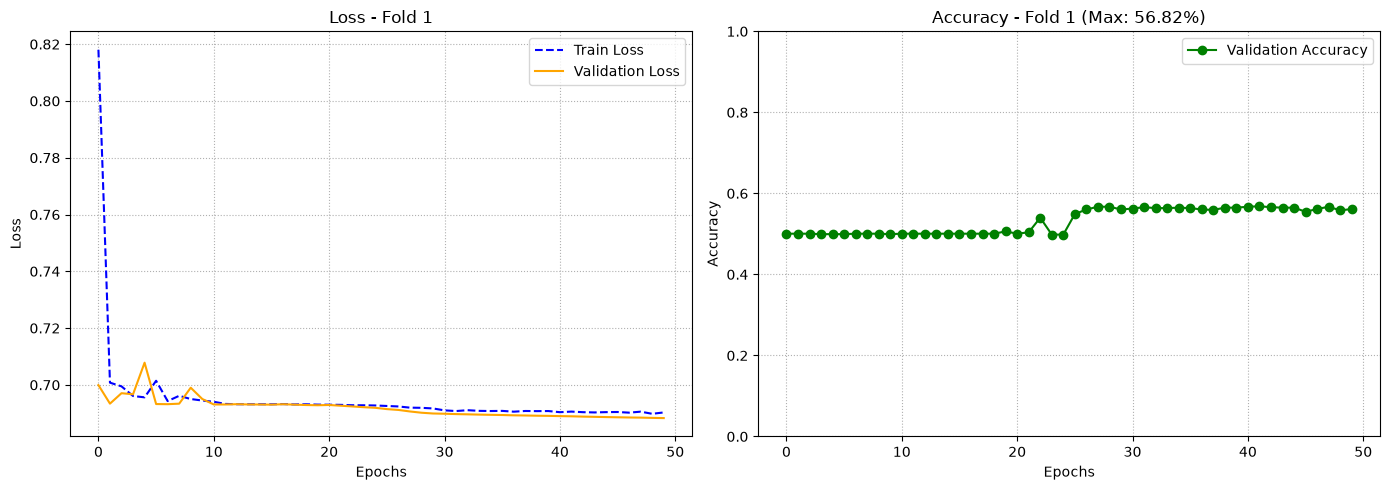


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 56.82% (± 0.00%)


In [ ]:


from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt
from torch.optim.lr_scheduler import MultiStepLR


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 3, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = MultiStepLR(optimizer, milestones=[10, 30], gamma=0.1)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

### f_CTrans with ReduceLROnPlateau

In this section, visto lo stagnare della val_acc, ho cambiato lo scheduler per poter adattare il tasso di apprendimento in tempo reale

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.78384, train_acc=49.33%, val_loss=0.69565, val_acc=49.94% | LR: 0.001000
Epoch 02/50: train_loss=0.69906, train_acc=49.27%, val_loss=0.69351, val_acc=50.06% | LR: 0.001000
Epoch 03/50: train_loss=0.69704, train_acc=49.10%, val_loss=0.69316, val_acc=50.06% | LR: 0.001000
Epoch 04/50: train_loss=0.69776, train_acc=50.65%, val_loss=0.69311, val_acc=49.94% | LR: 0.001000
Epoch 05/50: train_loss=0.69653, train_acc=50.04%, val_loss=0.69316, val_acc=49.94% | LR: 0.001000
Epoch 06/50: train_loss=0.69528, train_acc=49.61%, val_loss=0.69638, val_acc=49.94% | L

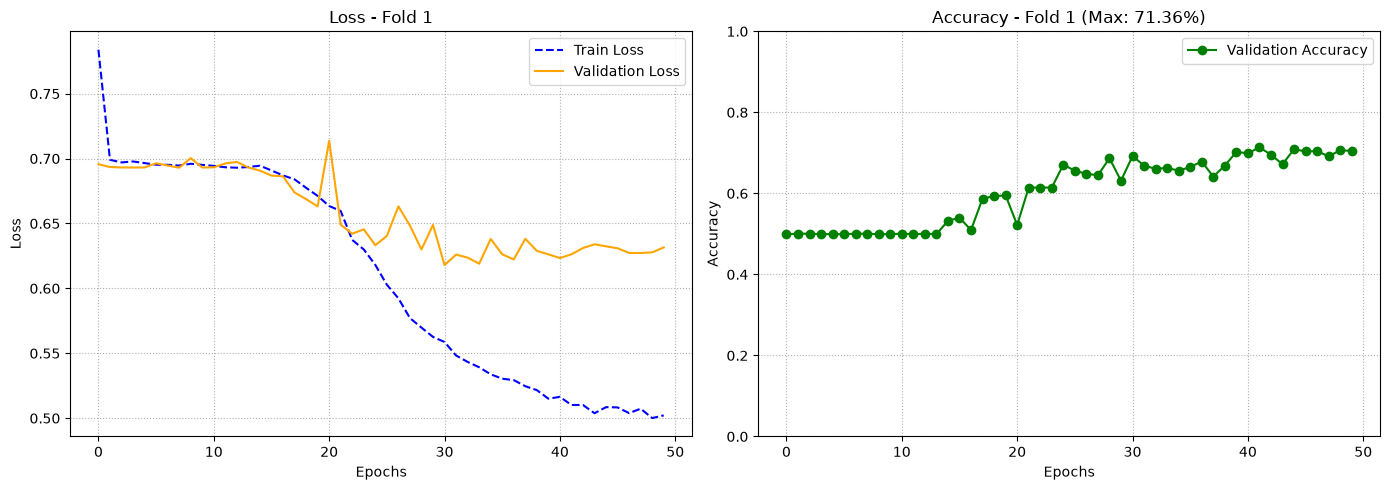


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 71.36% (± 0.00%)


In [ ]:
'''
#   Qui sbaglaivo perchè nel training avevo messo  ma nello scheduler usavo mode=max controllando la val_acc

#if scheduler is not None:
#    if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
#        scheduler.step(val_loss)  # ReduceLROnPlateau esige la validation loss
#    else:
#        scheduler.step()    


from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 3, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")
'''

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.76707, train_acc=49.01%, val_loss=0.69509, val_acc=50.06% | LR: 0.001000
Epoch 02/50: train_loss=0.70038, train_acc=48.46%, val_loss=0.69319, val_acc=49.94% | LR: 0.001000
Epoch 03/50: train_loss=0.69765, train_acc=49.73%, val_loss=0.69588, val_acc=49.94% | LR: 0.001000
Epoch 04/50: train_loss=0.69692, train_acc=50.67%, val_loss=0.69370, val_acc=49.94% | LR: 0.001000
Epoch 05/50: train_loss=0.69826, train_acc=49.38%, val_loss=0.69718, val_acc=50.06% | LR: 0.001000
Epoch 06/50: train_loss=0.69423, train_acc=49.64%, val_loss=0.69306, val_acc=49.94% | L

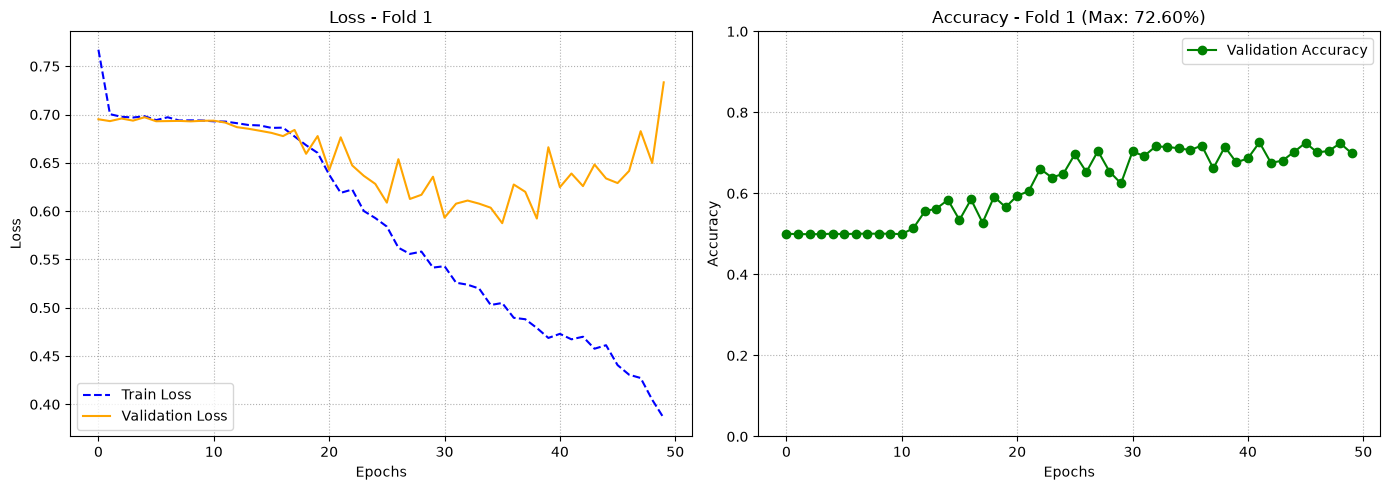


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 72.60% (± 0.00%)


In [ ]:


from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 3, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

Avendo notato l'overfitting ho provato ad aumentare il dropout

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.80584, train_acc=49.18%, val_loss=0.69400, val_acc=49.94% | LR: 0.001000
Epoch 02/50: train_loss=0.69684, train_acc=50.04%, val_loss=0.69899, val_acc=50.06% | LR: 0.001000
Epoch 03/50: train_loss=0.69868, train_acc=49.55%, val_loss=0.69767, val_acc=49.94% | LR: 0.001000
Epoch 04/50: train_loss=0.69720, train_acc=49.38%, val_loss=0.69421, val_acc=50.06% | LR: 0.001000
Epoch 05/50: train_loss=0.69542, train_acc=49.84%, val_loss=0.69355, val_acc=49.94% | LR: 0.001000
Epoch 06/50: train_loss=0.69639, train_acc=50.39%, val_loss=0.69941, val_acc=50.06% | L

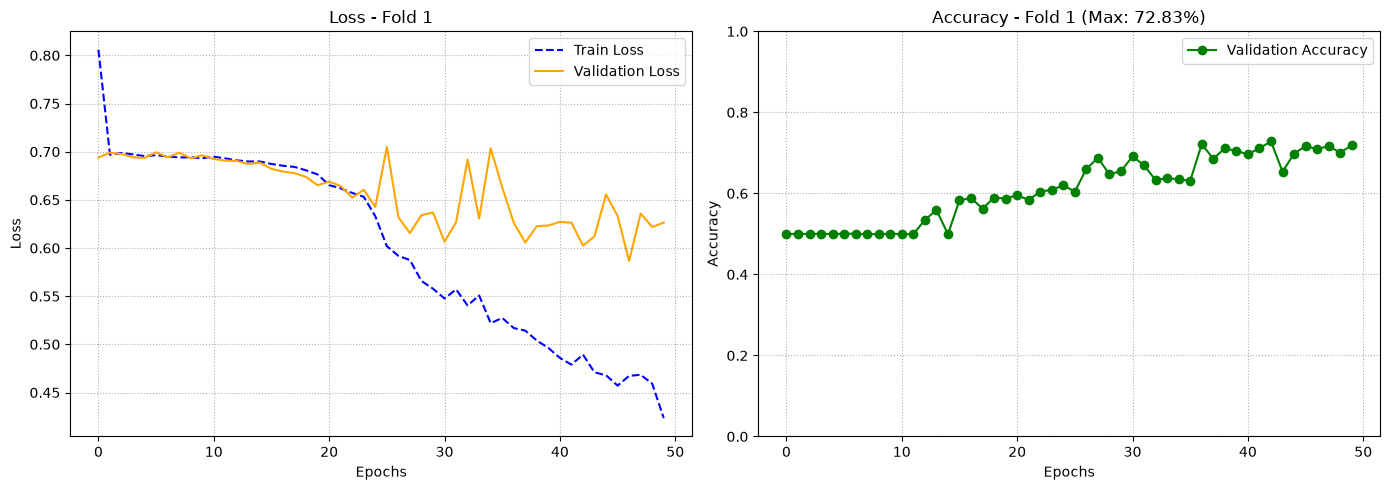


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 72.83% (± 0.00%)


In [14]:
# aumento dropout

from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.4, num_layers = 3, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

DIMINUISCO NUMERO LAYER

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.75167, train_acc=50.85%, val_loss=0.69433, val_acc=49.94% | LR: 0.001000
Epoch 02/50: train_loss=0.70518, train_acc=50.36%, val_loss=0.69362, val_acc=49.94% | LR: 0.001000
Epoch 03/50: train_loss=0.69955, train_acc=51.34%, val_loss=0.69419, val_acc=50.06% | LR: 0.001000
Epoch 04/50: train_loss=0.69597, train_acc=49.87%, val_loss=0.69517, val_acc=49.94% | LR: 0.001000
Epoch 05/50: train_loss=0.69623, train_acc=49.64%, val_loss=0.69361, val_acc=49.94% | LR: 0.001000
Epoch 06/50: train_loss=0.69587, train_acc=50.88%, val_loss=0.69503, val_acc=49.94% | L

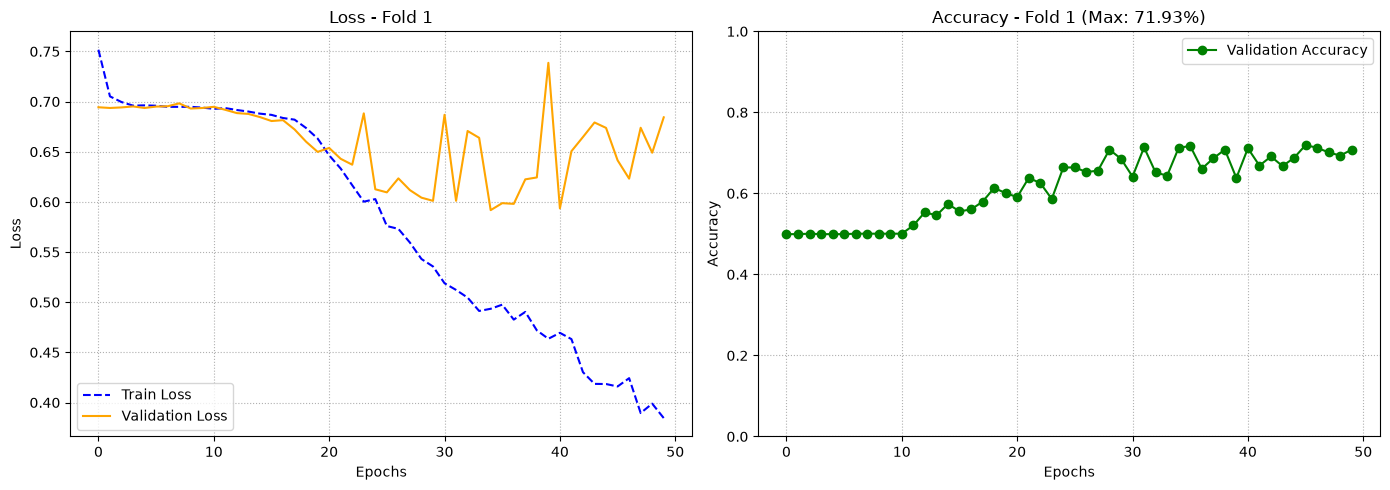


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 71.93% (± 0.00%)


In [10]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 2, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

N_L=2 E DROPOUT AUMENTATO 

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.76843, train_acc=51.34%, val_loss=0.70439, val_acc=50.06% | LR: 0.001000
Epoch 02/50: train_loss=0.69930, train_acc=50.22%, val_loss=0.70421, val_acc=50.06% | LR: 0.001000
Epoch 03/50: train_loss=0.69903, train_acc=48.75%, val_loss=0.70425, val_acc=50.06% | LR: 0.001000
Epoch 04/50: train_loss=0.69647, train_acc=50.73%, val_loss=0.69746, val_acc=49.94% | LR: 0.001000
Epoch 05/50: train_loss=0.69605, train_acc=50.67%, val_loss=0.69712, val_acc=49.94% | LR: 0.001000
Epoch 06/50: train_loss=0.69463, train_acc=50.73%, val_loss=0.69535, val_acc=49.94% | L

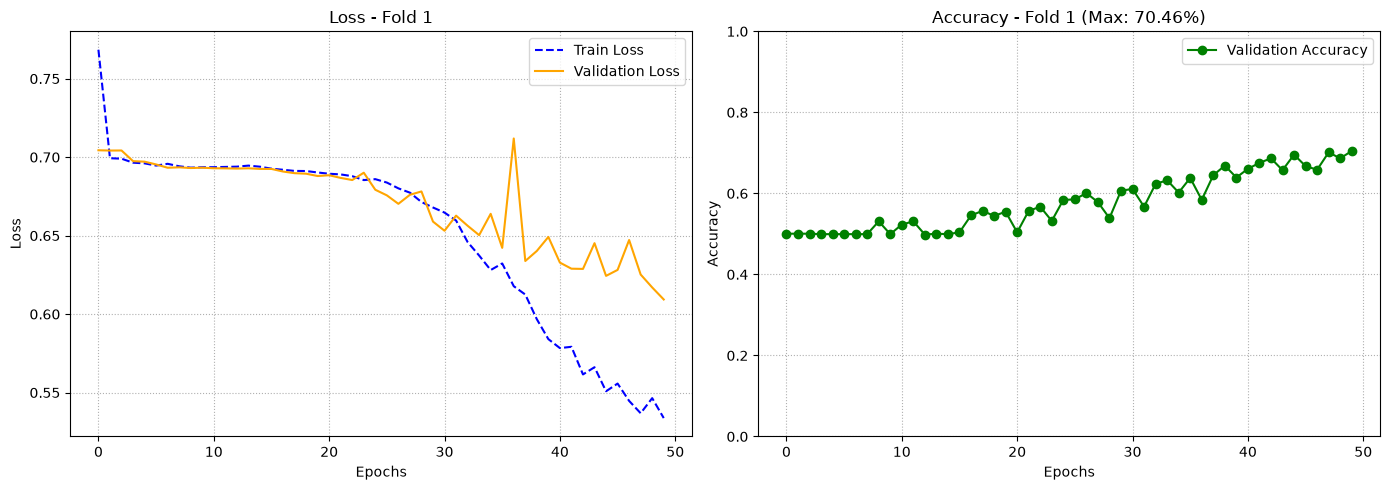


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 70.46% (± 0.00%)


In [ ]:
#aumento dropout

from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.4, num_layers = 2, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

### f_CTrans_modified with MultiStepLR

scheduler = MultiStepLR(optimizer, milestones=[10, 30], gamma=0.1)

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Epoch 01/50: train_loss=0.72457, train_acc=49.76%, val_loss=0.69857, val_acc=49.94% | LR: 0.001000
Epoch 02/50: train_loss=0.69811, train_acc=50.73%, val_loss=0.69593, val_acc=49.94% | LR: 0.001000
Epoch 03/50: train_loss=0.69482, train_acc=50.45%, val_loss=0.69313, val_acc=49.38% | LR: 0.001000
Epoch 04/50: train_loss=0.69470, train_acc=51.28%, val_loss=0.69379, val_acc=50.06% | LR: 0.001000
Epoch 05/50: train_loss=0.69482, train_acc=51.05%, val_loss=0.69413, val_acc=50.06% | LR: 0.001000
Epoch 06/50: train_loss=0.69507, train_acc=49.33%, val_loss=0.69358, val_acc=49.94% | LR: 0.001000
Epoch 07/50: train_loss=0.69545, train_acc=50.01%, val_loss=0.69349, val_acc=49.94% | LR: 0.001000
Epoch 08/50: train_loss=0.69385, train_acc=50.19%, val_loss=0.69389, val_acc=49.94% | LR: 0.001000
Epoch 09/50: train_loss=0.69410, train_acc=48.38%, val_loss=0.69346, val_acc=50.06% | LR: 0.001000
Epoch 10/50: train_los

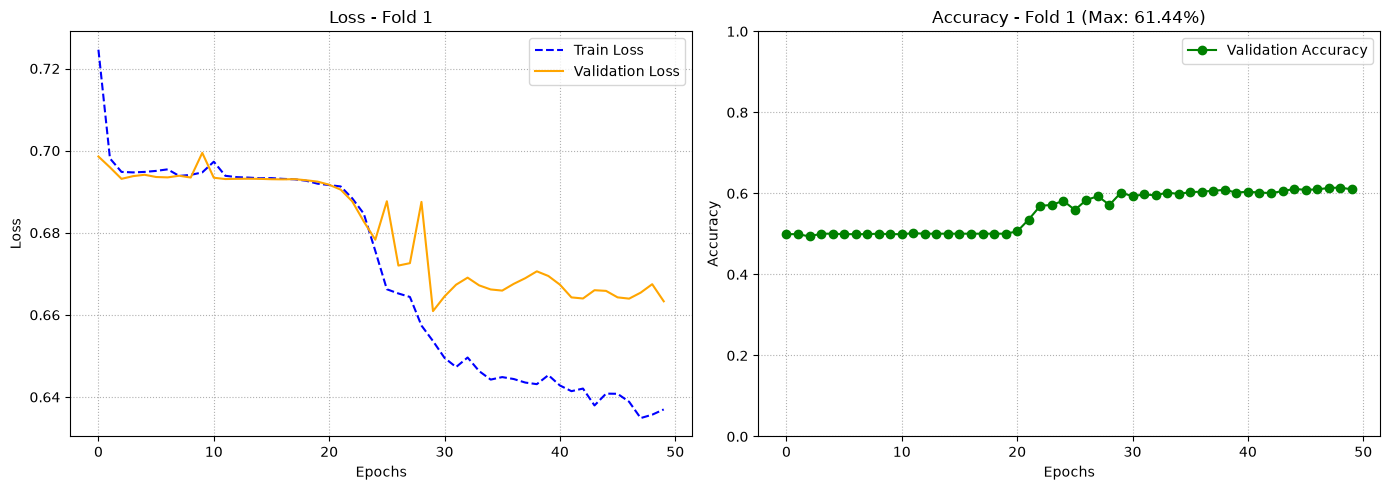


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 61.44% (± 0.00%)


In [15]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans_modified(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 3, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = MultiStepLR(optimizer, milestones=[10, 30], gamma=0.1)  
    
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)


   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

non noto overfitting, non aumento dropout

### F_CTrans_modified with ReduceLROnPlateau

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.70944, train_acc=48.55%, val_loss=0.69495, val_acc=49.94% | LR: 0.001000
Epoch 02/50: train_loss=0.69757, train_acc=49.35%, val_loss=0.70280, val_acc=50.06% | LR: 0.001000
Epoch 03/50: train_loss=0.69481, train_acc=49.55%, val_loss=0.70545, val_acc=50.06% | LR: 0.001000
Epoch 04/50: train_loss=0.69823, train_acc=48.64%, val_loss=0.69461, val_acc=49.94% | LR: 0.001000
Epoch 05/50: train_loss=0.69514, train_acc=49.90%, val_loss=0.69343, val_acc=50.06% | LR: 0.001000
Epoch 06/50: train_loss=0.69537, train_acc=50.07%, val_loss=0.69408, val_acc=50.06% | L

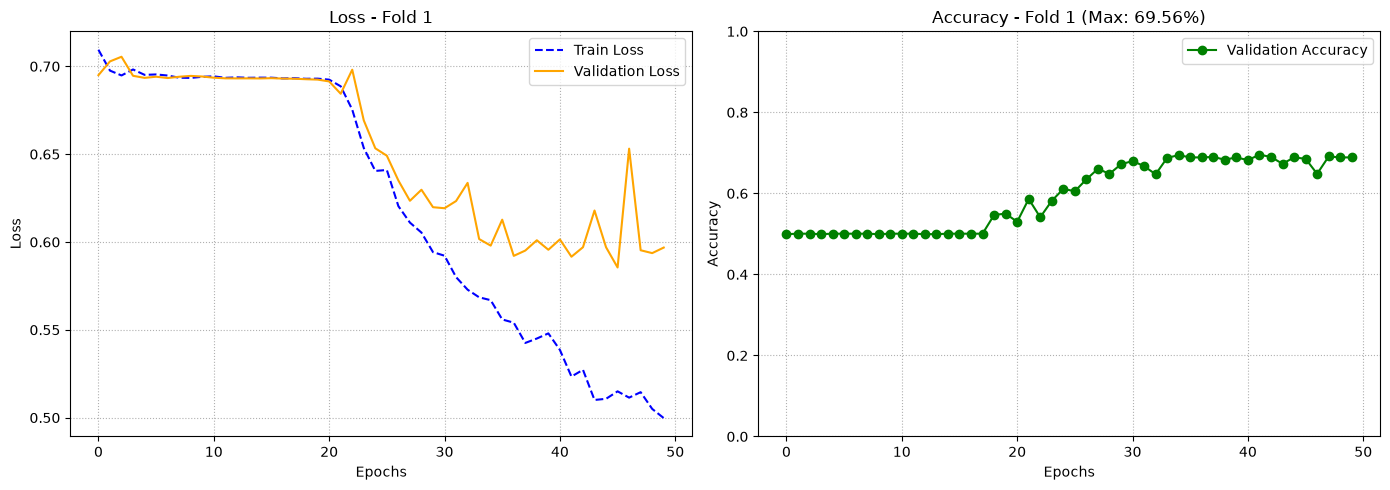


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 69.56% (± 0.00%)


In [16]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans_modified(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 3, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

non noto overfitting ma che succede se aumento il dropout??

qui provo con 2 layer

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.72517, train_acc=49.73%, val_loss=0.69417, val_acc=50.06% | LR: 0.001000
Epoch 02/50: train_loss=0.69575, train_acc=51.13%, val_loss=0.69324, val_acc=49.94% | LR: 0.001000
Epoch 03/50: train_loss=0.69608, train_acc=50.76%, val_loss=0.69313, val_acc=50.06% | LR: 0.001000
Epoch 04/50: train_loss=0.69363, train_acc=52.66%, val_loss=0.69381, val_acc=49.94% | LR: 0.001000
Epoch 05/50: train_loss=0.69580, train_acc=49.67%, val_loss=0.69384, val_acc=50.06% | LR: 0.001000
Epoch 06/50: train_loss=0.69518, train_acc=49.90%, val_loss=0.69438, val_acc=50.06% | L

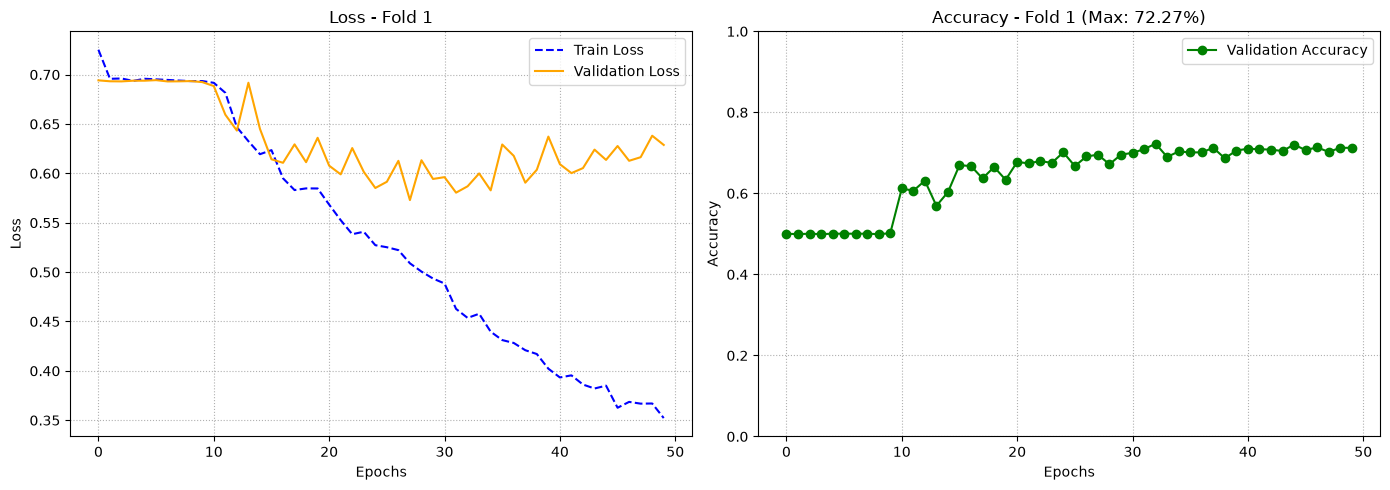


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 72.27% (± 0.00%)


In [17]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans_modified(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 2, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

noto overfitting, faccio dropout a 4

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.72476, train_acc=49.61%, val_loss=0.69722, val_acc=49.94% | LR: 0.001000
Epoch 02/50: train_loss=0.69715, train_acc=49.50%, val_loss=0.69397, val_acc=49.94% | LR: 0.001000
Epoch 03/50: train_loss=0.69697, train_acc=49.53%, val_loss=0.69420, val_acc=50.06% | LR: 0.001000
Epoch 04/50: train_loss=0.69436, train_acc=50.93%, val_loss=0.69501, val_acc=50.06% | LR: 0.001000
Epoch 05/50: train_loss=0.69669, train_acc=49.53%, val_loss=0.69357, val_acc=50.06% | LR: 0.001000
Epoch 06/50: train_loss=0.69601, train_acc=50.36%, val_loss=0.69322, val_acc=49.94% | L

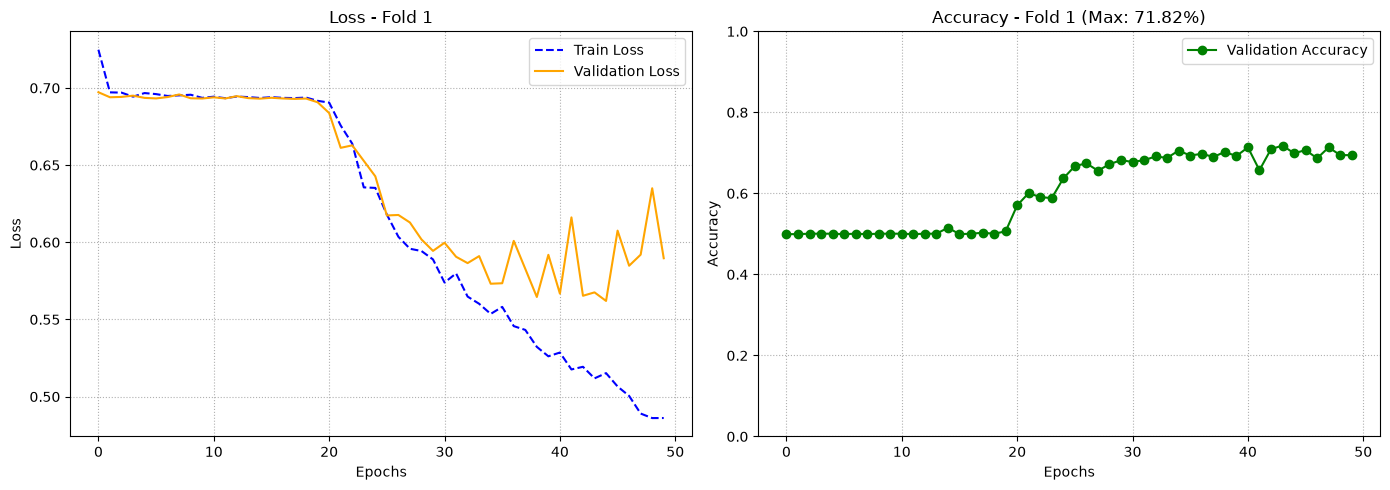


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 71.82% (± 0.00%)


In [18]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans_modified(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.4, num_layers = 2, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

aumento anciora dropout --> è troppo

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.71049, train_acc=49.18%, val_loss=0.69303, val_acc=51.07% | LR: 0.001000
Epoch 02/50: train_loss=0.69609, train_acc=48.81%, val_loss=0.69337, val_acc=49.94% | LR: 0.001000
Epoch 03/50: train_loss=0.69680, train_acc=47.92%, val_loss=0.69557, val_acc=49.94% | LR: 0.001000
Epoch 04/50: train_loss=0.69619, train_acc=49.93%, val_loss=0.69328, val_acc=50.06% | LR: 0.001000
Epoch 05/50: train_loss=0.69530, train_acc=49.70%, val_loss=0.69338, val_acc=49.94% | LR: 0.001000
Epoch 06/50: train_loss=0.69535, train_acc=50.36%, val_loss=0.69339, val_acc=49.94% | L

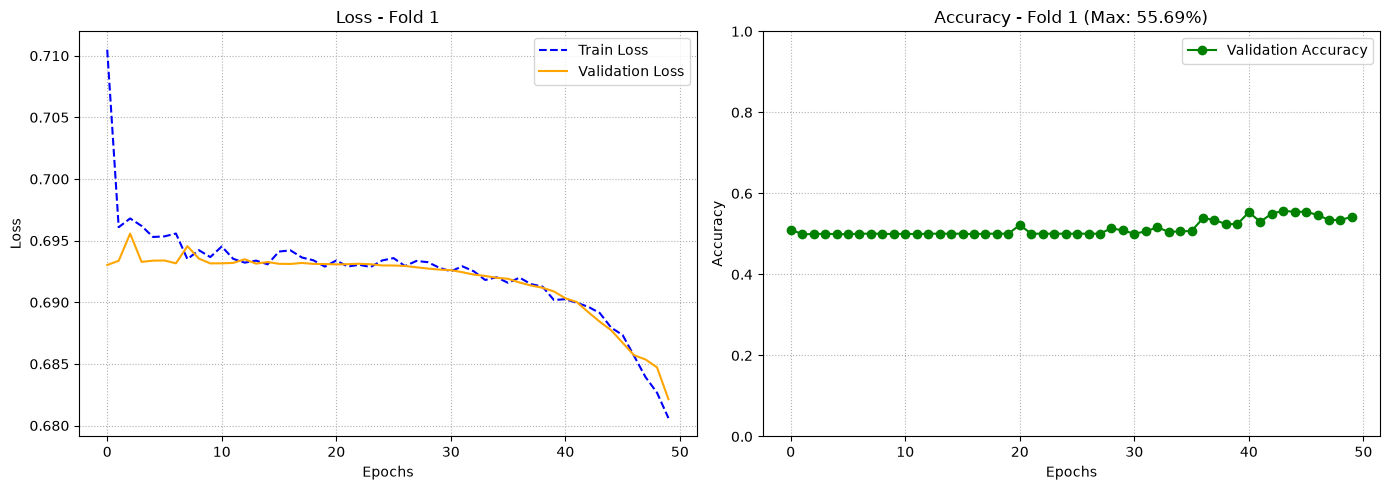


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 55.69% (± 0.00%)


In [19]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans_modified(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.5, num_layers = 2, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

## Mi concentro sul modello che reputo migliore

### aumento ancora un poco il dropout

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)


/home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/venv/lib/python3.12/site-packages/torch/nn/modules/conv.py:560: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1104.)
  return F.conv2d(


Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.70638, train_acc=50.47%, val_loss=0.69940, val_acc=50.06% | LR: 0.001000
Epoch 02/50: train_loss=0.69930, train_acc=49.10%, val_loss=0.69321, val_acc=49.94% | LR: 0.001000
Epoch 03/50: train_loss=0.69407, train_acc=51.45%, val_loss=0.69422, val_acc=50.06% | LR: 0.001000
Epoch 04/50: train_loss=0.69534, train_acc=50.56%, val_loss=0.69329, val_acc=50.06% | LR: 0.001000
Epoch 05/50: train_loss=0.69581, train_acc=50.16%, val_loss=0.69373, val_acc=49.94% | LR: 0.001000
Epoch 06/50: train_loss=0.69520, train_acc=48.72%, val_loss=0.69319, val_acc=49.94% | LR: 0.001000
Epoch 07/50: train_loss=0.69429, train_acc=49.64%, val_loss=0.69311, val_acc=50.85% | LR: 0.001000
Epoch 08/50: train_loss=0.69503, train_acc=50.10%, val_loss=0.69534, val_acc=49.94% | LR: 0.001000
Epoch 09/50: train_loss=0.69442, train_acc=50.96%, val_loss=0.69405, val_acc=49.94% | LR: 0.

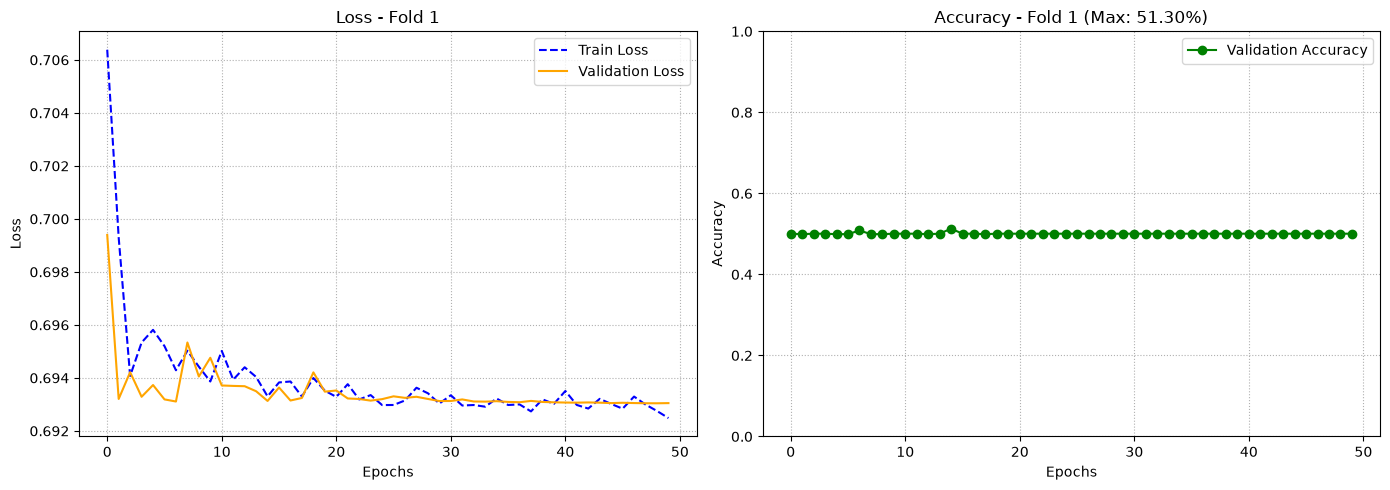


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 51.30% (± 0.00%)


In [ ]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans_modified(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.45, num_layers = 2, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

### Grid search su lr e weight decay sul pirmo fold

Detected device: GPU NVIDIA (CUDA)
--- COMBINATION 1/6 ---
Current parameters: {'lr': 0.001, 'weight_decay': 0.0001}
--- FOLD 1/1 (Screening) ---
Epoch 01/50: train_loss=0.70512, train_acc=50.24%, val_loss=0.69318, val_acc=49.94% | LR: 0.001000
Epoch 02/50: train_loss=0.69727, train_acc=49.78%, val_loss=0.69320, val_acc=50.06% | LR: 0.001000
Epoch 03/50: train_loss=0.69385, train_acc=50.30%, val_loss=0.69331, val_acc=49.94% | LR: 0.001000
Epoch 04/50: train_loss=0.69496, train_acc=49.90%, val_loss=0.69504, val_acc=50.06% | LR: 0.001000
Epoch 05/50: train_loss=0.69516, train_acc=50.24%, val_loss=0.69934, val_acc=49.94% | LR: 0.001000
Epoch 06/50: train_loss=0.69741, train_acc=48.81%, val_loss=0.69374, val_acc=49.94% | LR: 0.001000
Epoch 07/50: train_loss=0.69365, train_acc=49.78%, val_loss=0.69602, val_acc=50.06% | LR: 0.001000
Epoch 08/50: train_loss=0.69487, train_acc=49.84%, val_loss=0.69367, val_acc=49.94% | LR: 0.000500
Epoch 09/50: train_loss=0.69376, train_acc=51.59%, val_loss=0.

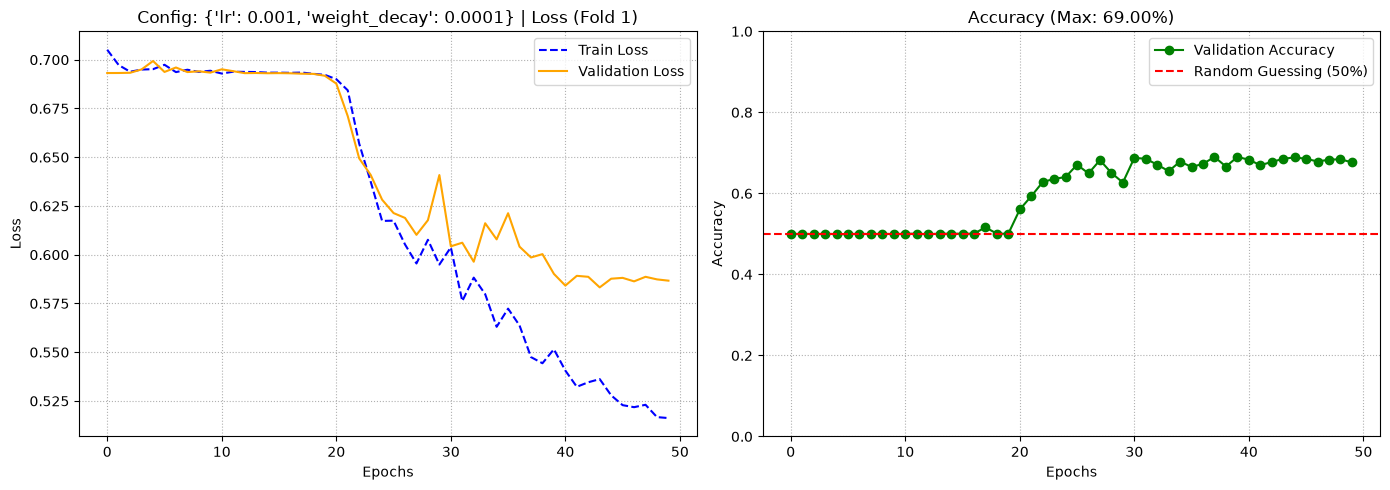

--- COMBINATION 2/6 ---
Current parameters: {'lr': 0.001, 'weight_decay': 0.0005}
--- FOLD 1/1 (Screening) ---
Epoch 01/50: train_loss=0.71859, train_acc=51.11%, val_loss=0.69752, val_acc=50.06% | LR: 0.001000
Epoch 02/50: train_loss=0.69927, train_acc=48.75%, val_loss=0.69312, val_acc=50.06% | LR: 0.001000
Epoch 03/50: train_loss=0.69677, train_acc=49.33%, val_loss=0.69393, val_acc=50.06% | LR: 0.001000
Epoch 04/50: train_loss=0.69436, train_acc=50.70%, val_loss=0.69332, val_acc=49.94% | LR: 0.001000
Epoch 05/50: train_loss=0.69698, train_acc=50.39%, val_loss=0.69382, val_acc=50.06% | LR: 0.001000
Epoch 06/50: train_loss=0.69501, train_acc=50.36%, val_loss=0.69394, val_acc=49.94% | LR: 0.001000
Epoch 07/50: train_loss=0.69641, train_acc=49.18%, val_loss=0.69312, val_acc=50.39% | LR: 0.001000
Epoch 08/50: train_loss=0.69345, train_acc=50.93%, val_loss=0.69489, val_acc=50.06% | LR: 0.001000
Epoch 09/50: train_loss=0.69452, train_acc=49.84%, val_loss=0.69304, val_acc=52.42% | LR: 0.00100

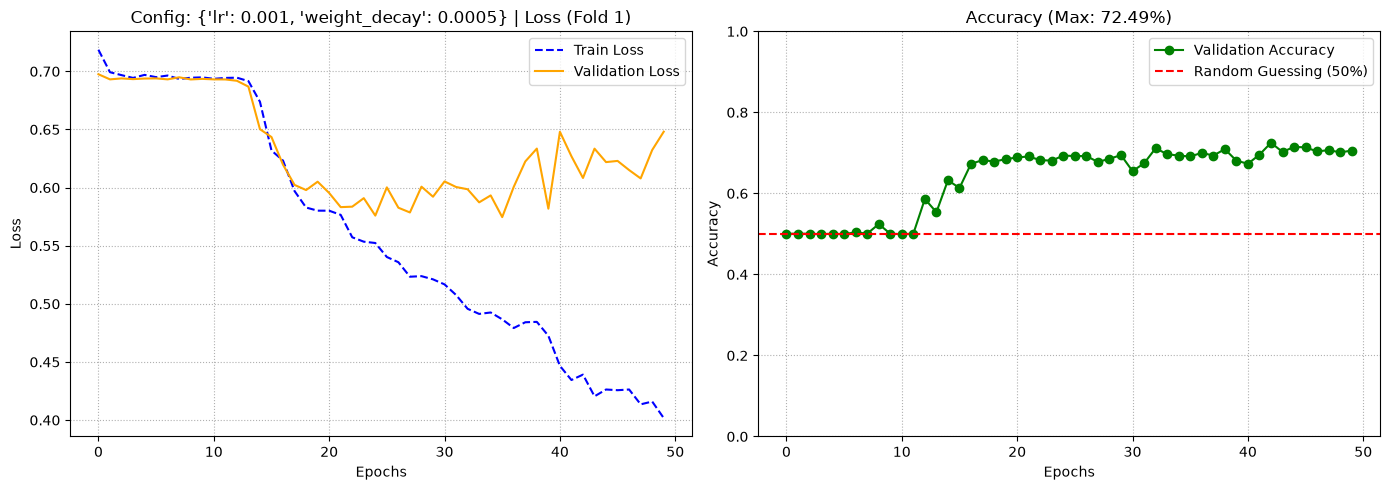

--- COMBINATION 3/6 ---
Current parameters: {'lr': 0.001, 'weight_decay': 0.001}
--- FOLD 1/1 (Screening) ---
Epoch 01/50: train_loss=0.72770, train_acc=49.38%, val_loss=0.69389, val_acc=49.94% | LR: 0.001000
Epoch 02/50: train_loss=0.69737, train_acc=48.38%, val_loss=0.69414, val_acc=50.06% | LR: 0.001000
Epoch 03/50: train_loss=0.69429, train_acc=52.25%, val_loss=0.69315, val_acc=50.06% | LR: 0.001000
Epoch 04/50: train_loss=0.69647, train_acc=49.07%, val_loss=0.69425, val_acc=49.94% | LR: 0.001000
Epoch 05/50: train_loss=0.69486, train_acc=50.07%, val_loss=0.69345, val_acc=50.06% | LR: 0.001000
Epoch 06/50: train_loss=0.69547, train_acc=50.01%, val_loss=0.69313, val_acc=50.39% | LR: 0.001000
Epoch 07/50: train_loss=0.69316, train_acc=52.60%, val_loss=0.69988, val_acc=49.94% | LR: 0.001000
Epoch 08/50: train_loss=0.69394, train_acc=50.76%, val_loss=0.69417, val_acc=49.94% | LR: 0.001000
Epoch 09/50: train_loss=0.69432, train_acc=50.42%, val_loss=0.69317, val_acc=50.06% | LR: 0.001000

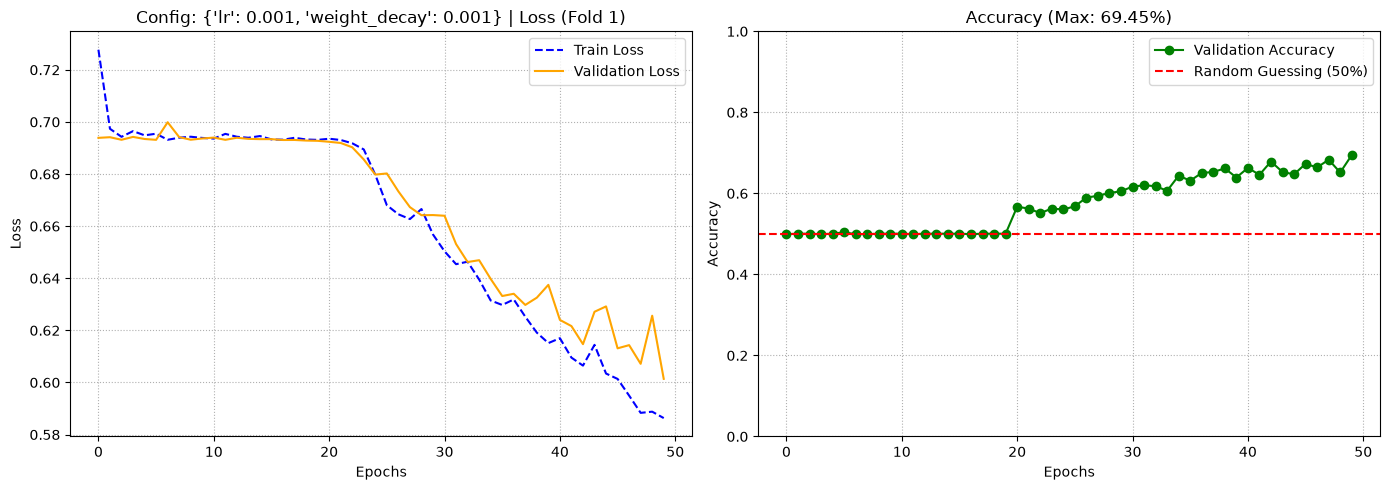

--- COMBINATION 4/6 ---
Current parameters: {'lr': 0.0005, 'weight_decay': 0.0001}
--- FOLD 1/1 (Screening) ---
Epoch 01/50: train_loss=0.70812, train_acc=49.78%, val_loss=0.69336, val_acc=50.06% | LR: 0.000500
Epoch 02/50: train_loss=0.69546, train_acc=49.90%, val_loss=0.69326, val_acc=50.06% | LR: 0.000500
Epoch 03/50: train_loss=0.69508, train_acc=49.21%, val_loss=0.69309, val_acc=51.30% | LR: 0.000500
Epoch 04/50: train_loss=0.69505, train_acc=49.84%, val_loss=0.69508, val_acc=50.06% | LR: 0.000500
Epoch 05/50: train_loss=0.69693, train_acc=50.04%, val_loss=0.69319, val_acc=49.94% | LR: 0.000500
Epoch 06/50: train_loss=0.69343, train_acc=50.79%, val_loss=0.69436, val_acc=50.06% | LR: 0.000500
Epoch 07/50: train_loss=0.69574, train_acc=49.78%, val_loss=0.69365, val_acc=49.94% | LR: 0.000500
Epoch 08/50: train_loss=0.69425, train_acc=49.87%, val_loss=0.69313, val_acc=50.06% | LR: 0.000500
Epoch 09/50: train_loss=0.69429, train_acc=50.45%, val_loss=0.69339, val_acc=49.94% | LR: 0.0002

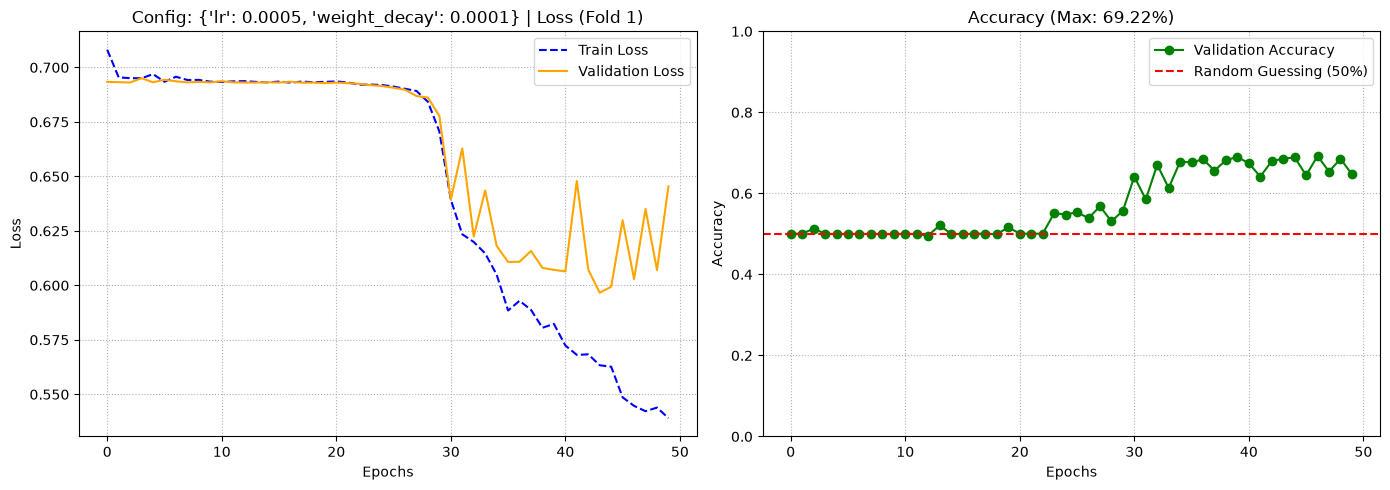

--- COMBINATION 5/6 ---
Current parameters: {'lr': 0.0005, 'weight_decay': 0.0005}
--- FOLD 1/1 (Screening) ---
Epoch 01/50: train_loss=0.71028, train_acc=50.45%, val_loss=0.70146, val_acc=50.06% | LR: 0.000500
Epoch 02/50: train_loss=0.69619, train_acc=49.70%, val_loss=0.69346, val_acc=49.94% | LR: 0.000500
Epoch 03/50: train_loss=0.69512, train_acc=49.58%, val_loss=0.69576, val_acc=49.94% | LR: 0.000500
Epoch 04/50: train_loss=0.69521, train_acc=50.47%, val_loss=0.69477, val_acc=50.06% | LR: 0.000500
Epoch 05/50: train_loss=0.69416, train_acc=50.65%, val_loss=0.69723, val_acc=49.94% | LR: 0.000500
Epoch 06/50: train_loss=0.69461, train_acc=50.79%, val_loss=0.69334, val_acc=50.06% | LR: 0.000500
Epoch 07/50: train_loss=0.69390, train_acc=49.53%, val_loss=0.69323, val_acc=49.94% | LR: 0.000250
Epoch 08/50: train_loss=0.69359, train_acc=50.76%, val_loss=0.69308, val_acc=51.52% | LR: 0.000250
Epoch 09/50: train_loss=0.69347, train_acc=50.45%, val_loss=0.69363, val_acc=50.06% | LR: 0.0002

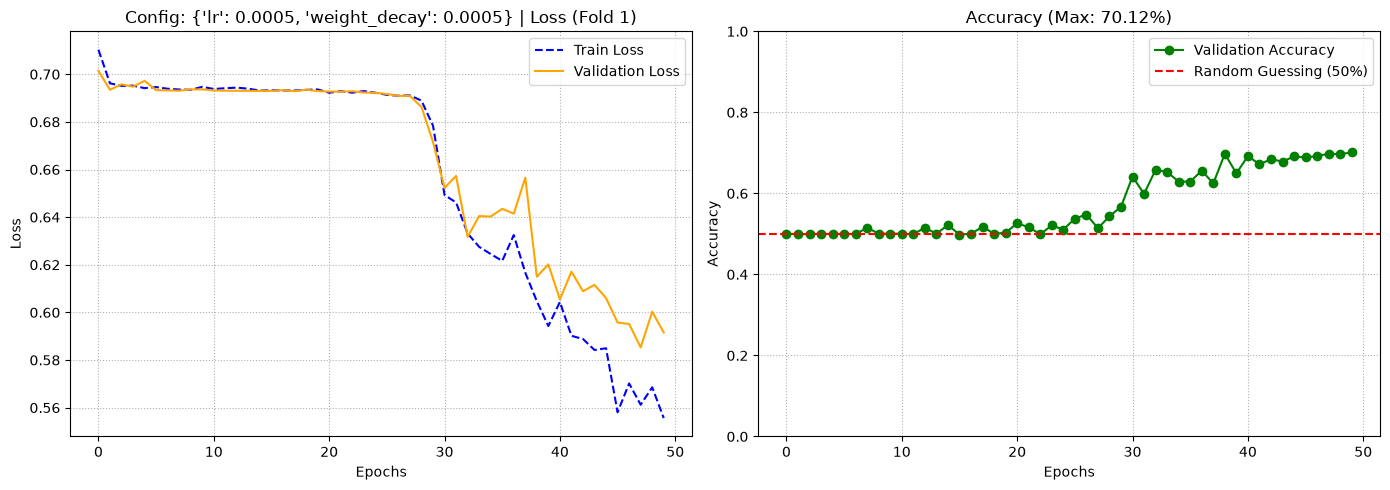

--- COMBINATION 6/6 ---
Current parameters: {'lr': 0.0005, 'weight_decay': 0.001}
--- FOLD 1/1 (Screening) ---
Epoch 01/50: train_loss=0.71197, train_acc=51.42%, val_loss=0.69544, val_acc=50.06% | LR: 0.000500
Epoch 02/50: train_loss=0.70250, train_acc=48.66%, val_loss=0.69314, val_acc=50.62% | LR: 0.000500
Epoch 03/50: train_loss=0.69498, train_acc=49.07%, val_loss=0.69358, val_acc=50.06% | LR: 0.000500
Epoch 04/50: train_loss=0.69302, train_acc=50.56%, val_loss=0.69905, val_acc=50.06% | LR: 0.000500
Epoch 05/50: train_loss=0.69540, train_acc=50.13%, val_loss=0.69357, val_acc=50.06% | LR: 0.000500
Epoch 06/50: train_loss=0.69488, train_acc=48.81%, val_loss=0.69309, val_acc=50.51% | LR: 0.000500
Epoch 07/50: train_loss=0.69439, train_acc=50.56%, val_loss=0.69326, val_acc=49.94% | LR: 0.000500
Epoch 08/50: train_loss=0.69440, train_acc=48.87%, val_loss=0.69313, val_acc=50.51% | LR: 0.000250
Epoch 09/50: train_loss=0.69424, train_acc=49.61%, val_loss=0.69331, val_acc=49.94% | LR: 0.00025

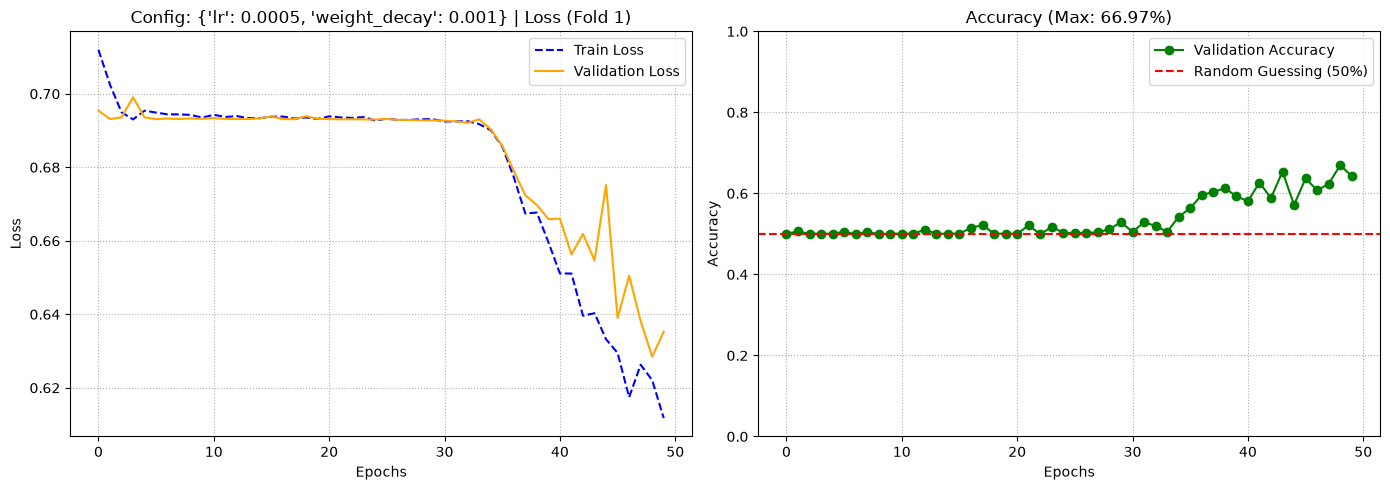


🎉 COMPLETE SCREENING SUMMARY (ON 1 FOLD):
Parameters {'lr': 0.001, 'weight_decay': 0.0001} ➔ Best Val Accuracy: 69.00%
Parameters {'lr': 0.001, 'weight_decay': 0.0005} ➔ Best Val Accuracy: 72.49%
Parameters {'lr': 0.001, 'weight_decay': 0.001} ➔ Best Val Accuracy: 69.45%
Parameters {'lr': 0.0005, 'weight_decay': 0.0001} ➔ Best Val Accuracy: 69.22%
Parameters {'lr': 0.0005, 'weight_decay': 0.0005} ➔ Best Val Accuracy: 70.12%
Parameters {'lr': 0.0005, 'weight_decay': 0.001} ➔ Best Val Accuracy: 66.97%

🏆 WINNING CONFIGURATION ON FOLD 1:
Parameters: {'lr': 0.001, 'weight_decay': 0.0005} with an accuracy of 72.49%


In [10]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt
from torch.optim.lr_scheduler import ReduceLROnPlateau
import itertools

if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")

param_grid = {
    'lr': [1e-3, 5e-4],
    'weight_decay': [1e-4, 5e-4, 1e-3]
}

keys = param_grid.keys()
values = param_grid.values()
param_combinations = [dict(zip(keys, combination)) for combination in itertools.product(*values)]

BATCH_SIZE = 64       
EPOCHS = 50           
ALPHA_NOISE = 0.01     
EPSILON = 1e-8


gkf = GroupKFold(n_splits=5)
grid_results = {}
best_global_acc = 0.0
best_model_state = None
best_params = None

for i, params in enumerate(param_combinations, 1):
    print(f"==========================================")
    print(f"--- COMBINATION {i}/{len(param_combinations)} ---")
    print(f"Current parameters: {params}")
    print(f"==========================================")
    
    for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
        
        print(f"--- FOLD 1/1 (Screening) ---")
        
        X_train_raw = X_training_validation_raw[train_idx]
        y_train = y_training_validation[train_idx]
        
        X_val_raw = X_training_validation_raw[val_idx]
        y_val = y_training_validation[val_idx]

        train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
        train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)

        X_train_norm = (X_train_raw - train_mean) / (train_std + EPSILON)
        noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
        X_train_final = X_train_norm + noise

        X_val_final = (X_val_raw - train_mean) / (train_std + EPSILON)

        train_dataset = EEGDataset(X_train_final, y_train)
        val_dataset = EEGDataset(X_val_final, y_val)

        train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

        model = F_CTrans_modified(num_channels=64, d_model=128, nhead=8, d_ff=512, dropout=0.4, num_layers=2, num_classes=2).to(device)
        
        criterion = nn.CrossEntropyLoss()
        optimizer = optim.Adam(model.parameters(), lr=params['lr'], betas=(0.9, 0.95), weight_decay=params['weight_decay'])
        scheduler = ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=5, min_lr=1e-6)
        
        trainer = EEGTrainer(model=model, criterion=criterion, optimizer=optimizer, device=device )
        
        best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader, epochs=EPOCHS, scheduler=scheduler)

        print(f"✅ Screening completed | Best Val Acc: {best_val_acc*100:.2f}%")

        if best_val_acc > best_global_acc:
            best_global_acc = best_val_acc
            best_model_state = model.state_dict()
            best_params = params

        grid_results[str(params)] = best_val_acc

        plt.figure(figsize=(14, 5))

        plt.subplot(1, 2, 1)
        plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
        plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
        plt.title(f'Config: {params} | Loss (Fold 1)')
        plt.xlabel('Epochs')
        plt.ylabel('Loss')
        plt.legend()
        plt.grid(True, linestyle=':')

        plt.subplot(1, 2, 2)
        plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
        plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
        plt.title(f'Accuracy (Max: {max(val_accuracies)*100:.2f}%)')
        plt.xlabel('Epochs')
        plt.ylabel('Accuracy')
        plt.ylim(0.0, 1.0)
        plt.legend()
        plt.grid(True, linestyle=':')

        plt.tight_layout()
        plt.show()

        break  
print(f"\n🎉 COMPLETE SCREENING SUMMARY (ON 1 FOLD):")
for config, acc in grid_results.items():
    print(f"Parameters {config} ➔ Best Val Accuracy: {acc*100:.2f}%")

print(f"\n🏆 WINNING CONFIGURATION ON FOLD 1:")
print(f"Parameters: {best_params} with an accuracy of {best_global_acc*100:.2f}%")

I parametri che più mi hanno convinta sono:
- {'lr': 0.001, 'weight_decay': 0.001}
- {'lr': 0.0005, 'weight_decay': 0.0005}

Provo ad allungare il numero di epoche solo su 1 fold


{'lr': 0.0005, 'weight_decay': 0.0005}


 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)


/home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/venv/lib/python3.12/site-packages/torch/nn/modules/conv.py:560: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1104.)
  return F.conv2d(


Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/70: train_loss=0.70504, train_acc=50.70%, val_loss=0.70075, val_acc=50.06% | LR: 0.000500
Epoch 02/70: train_loss=0.69656, train_acc=50.65%, val_loss=0.69316, val_acc=49.94% | LR: 0.000500
Epoch 03/70: train_loss=0.69434, train_acc=51.02%, val_loss=0.69313, val_acc=49.94% | LR: 0.000500
Epoch 04/70: train_loss=0.69481, train_acc=50.42%, val_loss=0.69316, val_acc=49.94% | LR: 0.000500
Epoch 05/70: train_loss=0.69536, train_acc=48.69%, val_loss=0.69359, val_acc=49.94% | LR: 0.000500
Epoch 06/70: train_loss=0.69512, train_acc=48.29%, val_loss=0.69312, val_acc=49.94% | LR: 0.000500
Epoch 07/70: train_loss=0.69439, train_acc=48.72%, val_loss=0.69315, val_acc=49.94% | LR: 0.000250
Epoch 08/70: train_loss=0.69366, train_acc=51.11%, val_loss=0.69391, val_acc=49.94% | LR: 0.000250
Epoch 09/70: train_loss=0.69438, train_acc=49.78%, val_loss=0.69398, val_acc=49.94% | LR: 0.

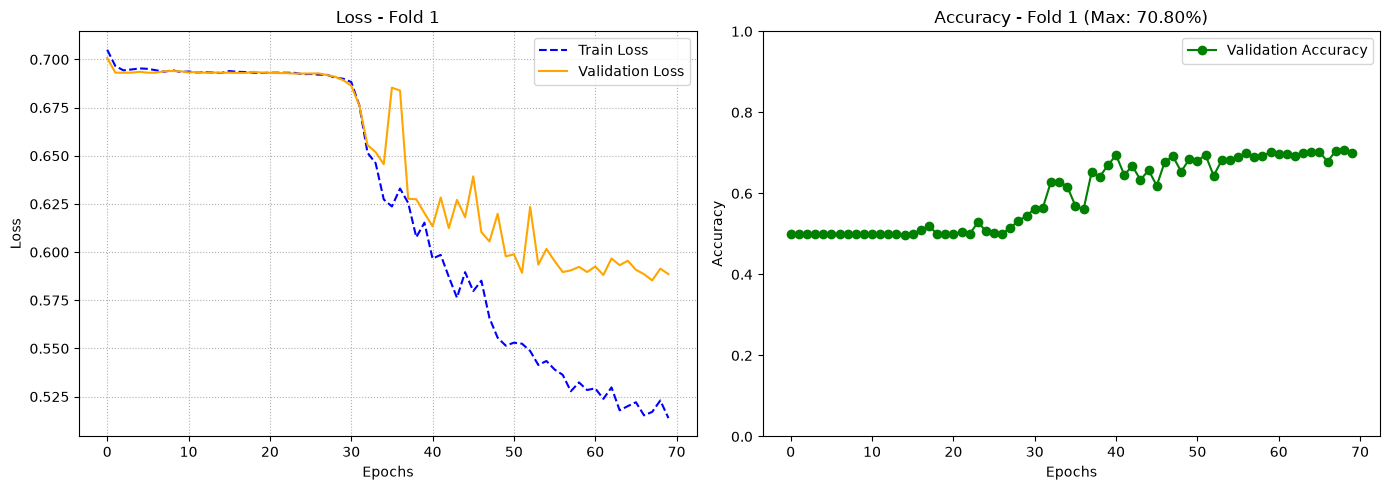


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 70.80% (± 0.00%)


In [7]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 70           
LR = 0.0005       
WEIGHT_DECAY = 0.0005  
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans_modified(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.4, num_layers = 2, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

{'lr': 0.001, 'weight_decay': 0.001}


 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/70: train_loss=0.72757, train_acc=50.22%, val_loss=0.69444, val_acc=50.06% | LR: 0.001000
Epoch 02/70: train_loss=0.69475, train_acc=51.19%, val_loss=0.69544, val_acc=49.94% | LR: 0.001000
Epoch 03/70: train_loss=0.69666, train_acc=50.36%, val_loss=0.69336, val_acc=50.06% | LR: 0.001000
Epoch 04/70: train_loss=0.69588, train_acc=49.18%, val_loss=0.69442, val_acc=50.06% | LR: 0.001000
Epoch 05/70: train_loss=0.69610, train_acc=48.58%, val_loss=0.69359, val_acc=49.94% | LR: 0.001000
Epoch 06/70: train_loss=0.69477, train_acc=50.39%, val_loss=0.69520, val_acc=50.06% | L

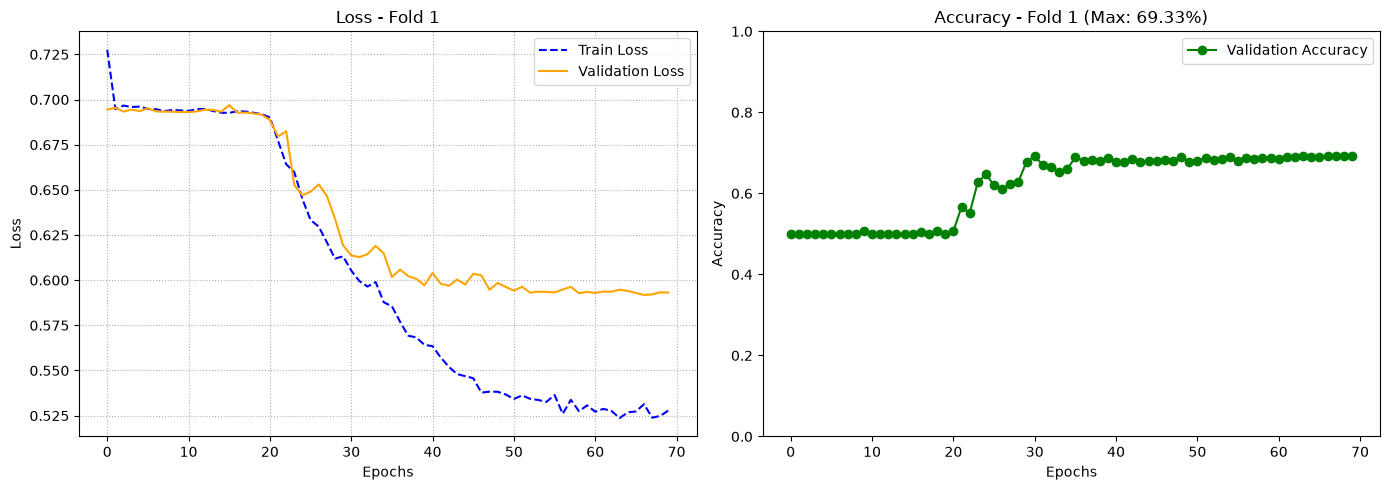


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 69.33% (± 0.00%)


In [8]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 70           
LR = 0.001 
WEIGHT_DECAY = 0.001 
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans_modified(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.4, num_layers = 2, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

### PROVO SU TUTTI I FOLD

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/70: train_loss=0.71271, train_acc=49.78%, val_loss=0.69656, val_acc=50.06% | LR: 0.000500
Epoch 02/70: train_loss=0.69679, train_acc=50.45%, val_loss=0.69310, val_acc=49.94% | LR: 0.000500
Epoch 03/70: train_loss=0.69612, train_acc=49.18%, val_loss=0.69334, val_acc=49.94% | LR: 0.000500
Epoch 04/70: train_loss=0.69547, train_acc=50.13%, val_loss=0.69314, val_acc=50.17% | LR: 0.000500
Epoch 05/70: train_loss=0.69457, train_acc=49.01%, val_loss=0.69346, val_acc=49.94% | LR: 0.000500
Epoch 06/70: train_loss=0.69471, train_acc=49.53%, val_loss=0.69457, val_acc=50.06% | L

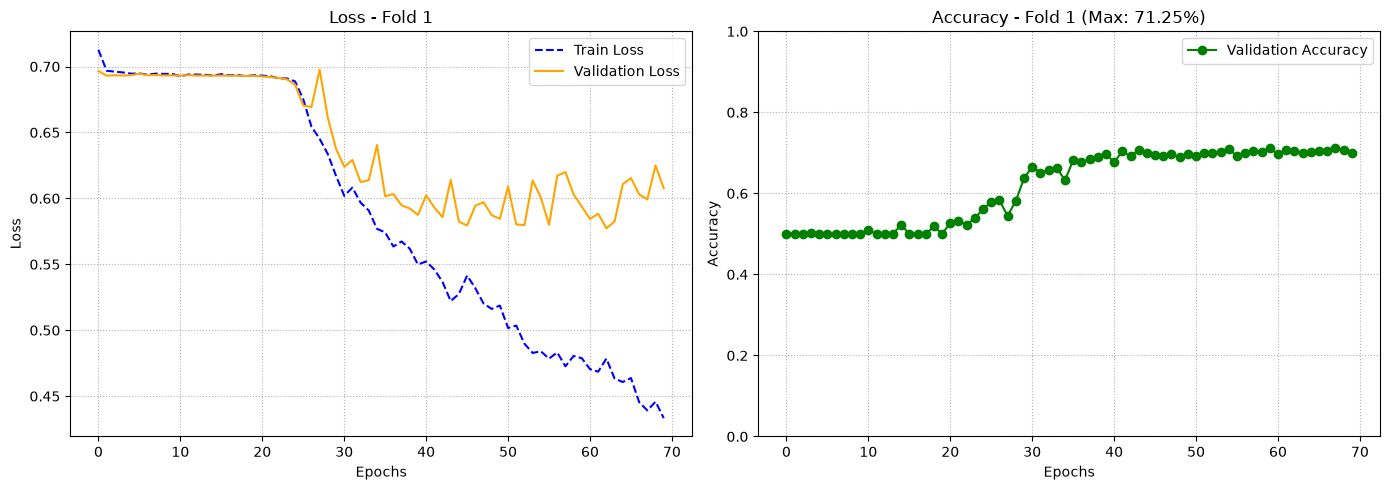


--- START TRAINING AND VALIDAZIONE - FOLD 2/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/70: train_loss=0.70425, train_acc=50.26%, val_loss=0.69316, val_acc=49.07% | LR: 0.000500
Epoch 02/70: train_loss=0.69705, train_acc=48.95%, val_loss=0.69316, val_acc=49.88% | LR: 0.000500
Epoch 03/70: train_loss=0.69682, train_acc=49.49%, val_loss=0.69349, val_acc=50.12% | LR: 0.000500
Epoch 04/70: train_loss=0.69352, train_acc=50.57%, val_loss=0.69556, val_acc=50.12% | LR: 0.000500
Epoch 05/70: train_loss=0.69387, train_acc=50.88%, val_loss=0.69322, val_acc=49.88% | LR: 0.000500
Epoch 06/70: train_loss=0.69341, train_acc=50.28%, val_loss=0.69596, val_acc=50.12% | LR: 0.000500
Epoch 07/70: train_loss=

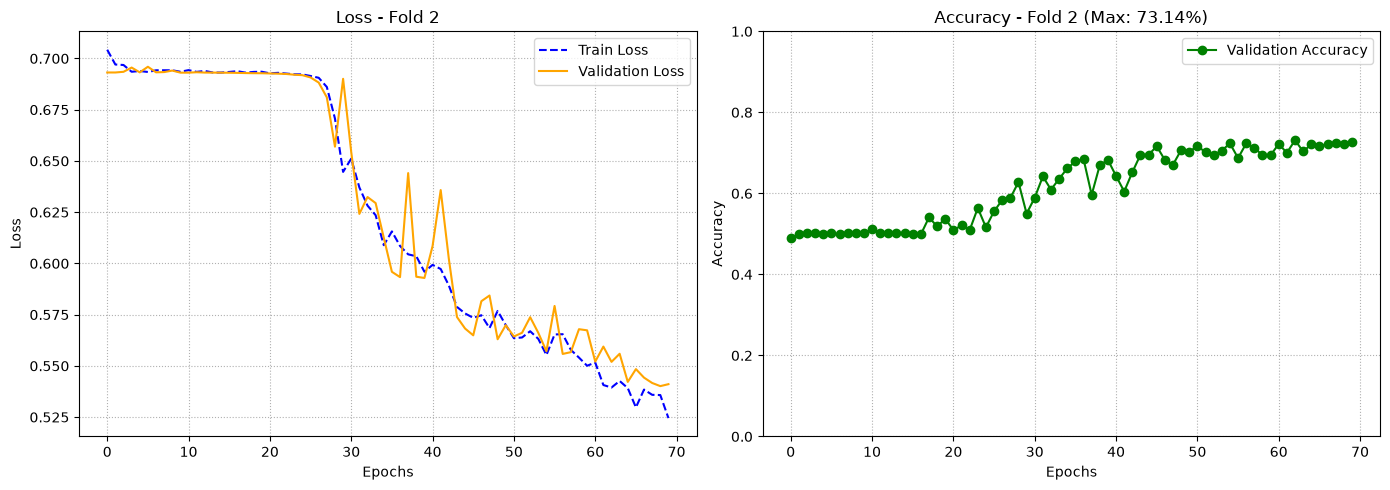


--- START TRAINING AND VALIDAZIONE - FOLD 3/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/70: train_loss=0.70804, train_acc=50.44%, val_loss=0.69324, val_acc=49.48% | LR: 0.000500
Epoch 02/70: train_loss=0.69722, train_acc=49.25%, val_loss=0.69303, val_acc=50.52% | LR: 0.000500
Epoch 03/70: train_loss=0.69477, train_acc=50.78%, val_loss=0.69338, val_acc=49.48% | LR: 0.000500
Epoch 04/70: train_loss=0.69565, train_acc=49.64%, val_loss=0.69318, val_acc=49.48% | LR: 0.000500
Epoch 05/70: train_loss=0.69425, train_acc=50.27%, val_loss=0.69329, val_acc=49.48% | LR: 0.000500
Epoch 06/70: train_loss=0.69481, train_acc=49.44%, val_loss=0.69377, val_acc=49.48% | LR: 0.000500
Epoch 07/70: train_loss=

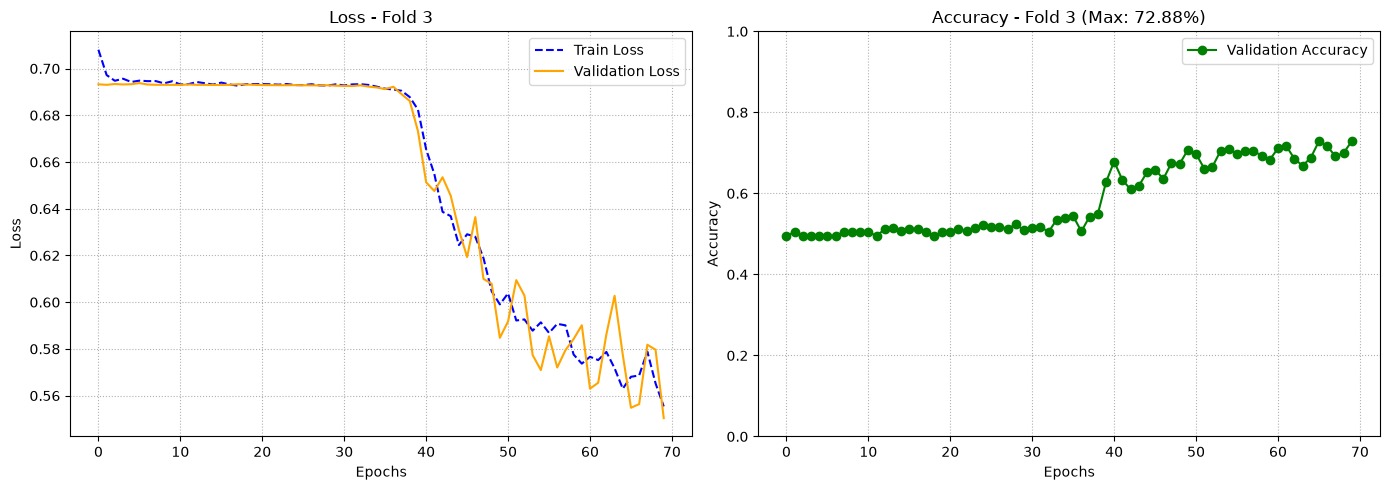


--- START TRAINING AND VALIDAZIONE - FOLD 4/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/70: train_loss=0.70647, train_acc=49.61%, val_loss=0.69364, val_acc=50.40% | LR: 0.000500
Epoch 02/70: train_loss=0.69491, train_acc=51.85%, val_loss=0.69412, val_acc=49.49% | LR: 0.000500
Epoch 03/70: train_loss=0.69421, train_acc=49.99%, val_loss=0.69317, val_acc=50.51% | LR: 0.000500
Epoch 04/70: train_loss=0.69499, train_acc=49.10%, val_loss=0.69403, val_acc=49.49% | LR: 0.000500
Epoch 05/70: train_loss=0.69481, train_acc=50.30%, val_loss=0.69556, val_acc=50.51% | LR: 0.000500
Epoch 06/70: train_loss=0.69462, train_acc=50.07%, val_loss=0.69338, val_acc=50.51% | LR: 0.000500
Epoch 07/70: train_loss=

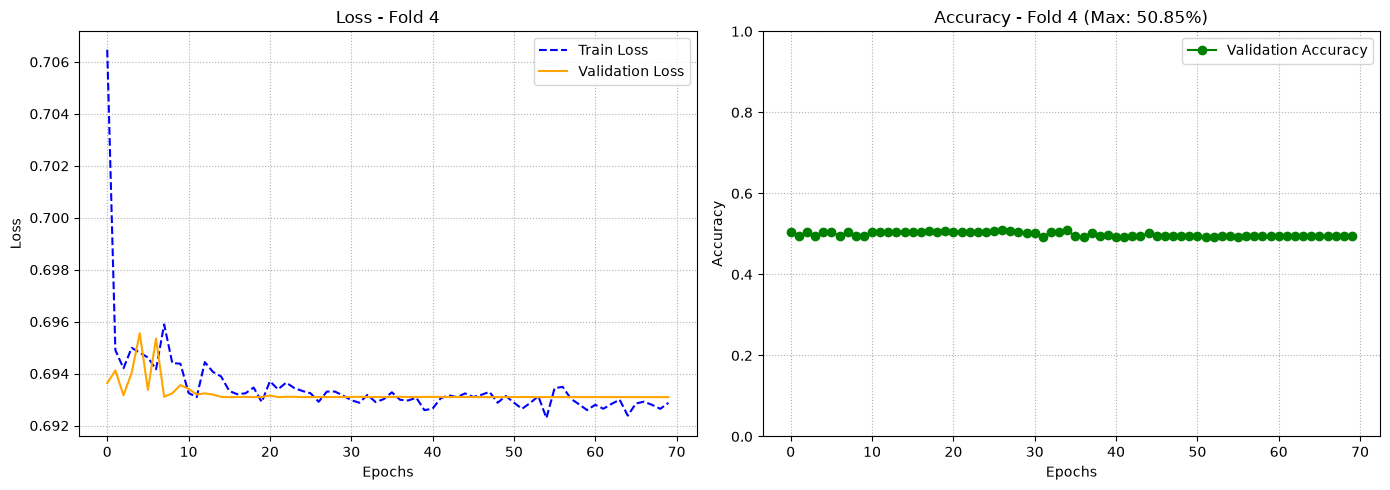


--- START TRAINING AND VALIDAZIONE - FOLD 5/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/70: train_loss=0.71090, train_acc=51.08%, val_loss=0.69305, val_acc=50.40% | LR: 0.000500
Epoch 02/70: train_loss=0.69799, train_acc=49.35%, val_loss=0.69286, val_acc=51.08% | LR: 0.000500
Epoch 03/70: train_loss=0.69618, train_acc=49.35%, val_loss=0.69328, val_acc=51.08% | LR: 0.000500
Epoch 04/70: train_loss=0.69472, train_acc=48.98%, val_loss=0.69694, val_acc=48.92% | LR: 0.000500
Epoch 05/70: train_loss=0.69428, train_acc=49.33%, val_loss=0.69288, val_acc=51.08% | LR: 0.000500
Epoch 06/70: train_loss=0.69539, train_acc=49.35%, val_loss=0.69384, val_acc=48.92% | LR: 0.000500
Epoch 07/70: train_loss=

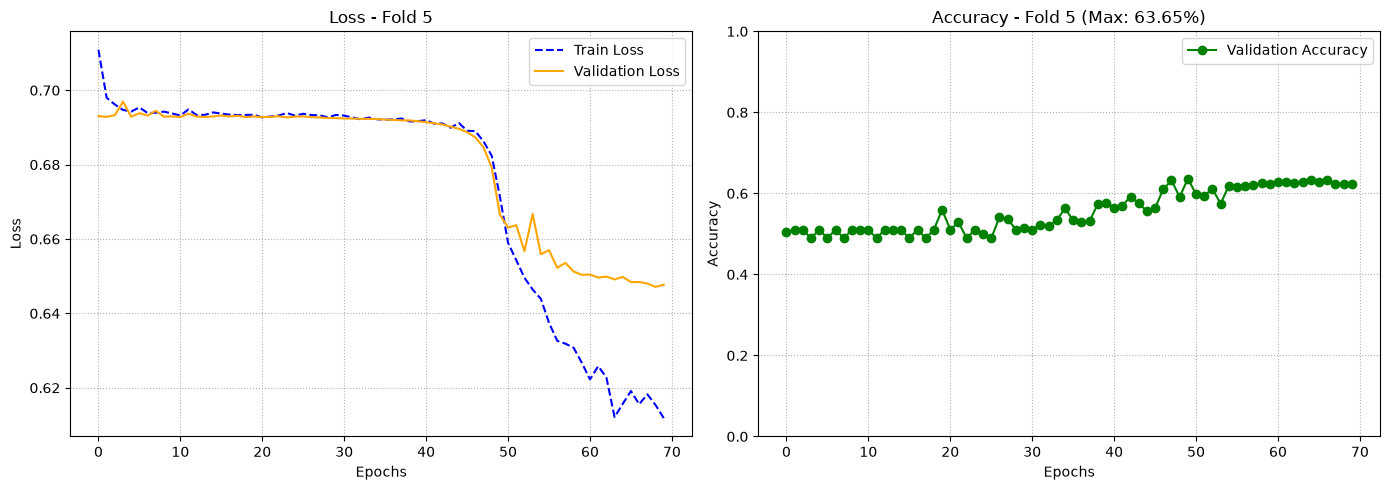


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 66.35% (± 8.49%)


In [9]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 70           
LR = 0.0005       
WEIGHT_DECAY = 0.0005  
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans_modified(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.4, num_layers = 2, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")